Dataset Shape: (569, 30)
Target Shape: (569,)

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ... 

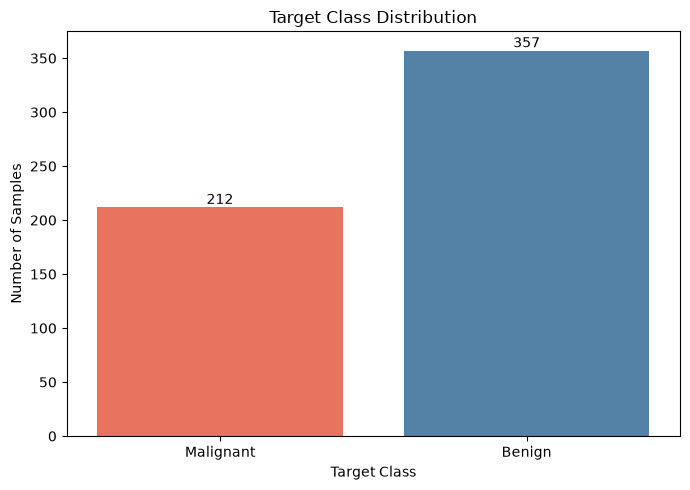

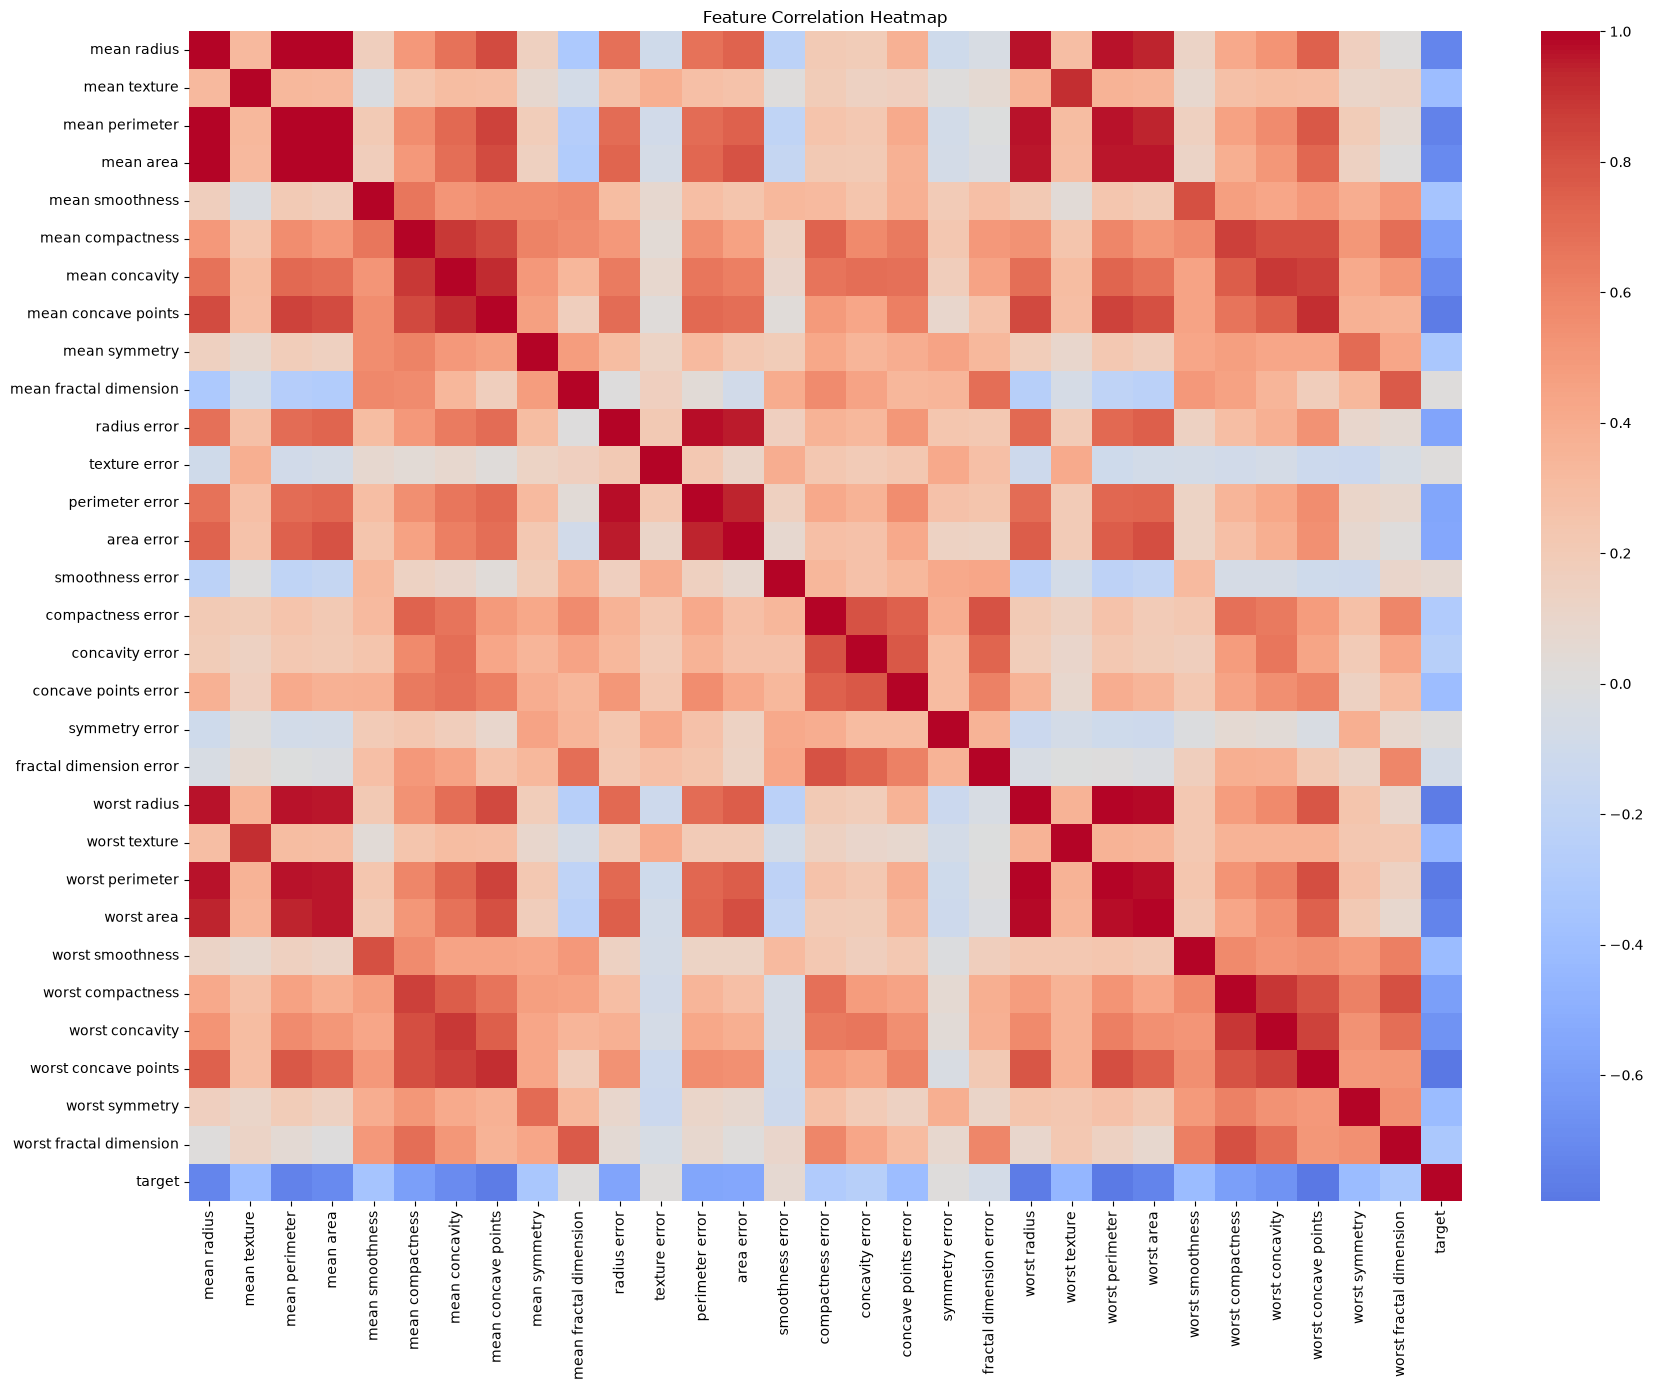

Top 10 Correlated Feature Pairs:
mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean radius      mean area          0.987357
mean perimeter   mean area          0.986507
worst radius     worst area         0.984015
worst perimeter  worst area         0.977578
radius error     perimeter error    0.972794
mean perimeter   worst perimeter    0.970387
mean radius      worst radius       0.969539
mean perimeter   worst radius       0.969476
dtype: float64
X_train Shape: (455, 30)
X_test Shape: (114, 30)
y_train Shape: (455,)
y_test Shape: (114,)

Training Class Distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing Class Distribution:
target
1    72
0    42
Name: count, dtype: int64
Scaled Training Shape: (455, 30)
Scaled Testing Shape: (114, 30)
First 5 feature means: [-0.  0. -0.  0.  0.]
First 5 feature standard deviations: [1. 1. 1. 1. 1.]

WHY SCALING IS IMPORTANT:

1. Features have different numerical ranges.
2. Large value

In [89]:
# Task - (1)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset [1.1]
data = load_breast_cancer(as_frame=True)

# Separate features and target
X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFirst 5 Rows:")
print(X.head())

print("\nTarget Distribution:")
print(y.value_counts().sort_index())

print("\nMissing Values:", X.isnull().sum().sum())

# Convert target numbers to labels
target_labels = y.map({
    0: "Malignant",
    1: "Benign"
})

# Class Distribution Plot [1.2]

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=target_labels,
    hue=target_labels,
    order=["Malignant", "Benign"],
    palette={
        "Malignant": "tomato",
        "Benign": "steelblue"
    },
    legend=False
)

plt.title("Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")

# Display counts on bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        str(int(height)),
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Feature Correlation Heatmap [1.3]

# Combine features and target
df = X.copy()
df["target"] = y

# Calculate correlation
correlation = df.corr(numeric_only=True)

# Plot heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Find highly correlated feature pairs
corr_abs = X.corr().abs()

upper = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

top_correlations = (
    upper.stack()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Correlated Feature Pairs:")
print(top_correlations)

# Train-Test Split [1.4]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

# Apply StandardScaler [1.5]

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using training statistics
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

print(
    "First 5 feature means:",
    np.round(X_train_scaled.mean(axis=0)[:5], 2)
)

print(
    "First 5 feature standard deviations:",
    np.round(X_train_scaled.std(axis=0)[:5], 2)
)

# Why scaling is important for neural networks [1.6]

print("""
WHY SCALING IS IMPORTANT:

1. Features have different numerical ranges.
2. Large values can dominate smaller-scale features.
3. StandardScaler puts features on a comparable scale.
4. Scaling helps gradient-based optimizers such as Adam
   and SGD train more reliably.
5. The scaler must be fitted only on training data to
   prevent data leakage.
""")

Model: "sequential_53"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_143 (Dense)                    │ (None, 1)                   │              31 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_143 (Dense)                    │ (None, 1)                   │              31 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.1540 - loss: 1.3751 - val_accuracy: 0.2391 - val_loss: 1.3197
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1858 - loss: 1.2465 - val_accuracy: 0.2609 - val_loss: 1.2042
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2200 - loss: 1.1279 - val_accuracy: 0.3261 - val_loss: 1.0983
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2763 - loss: 1.0201 - val_accuracy: 0.3913 - val_loss: 1.0030
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3178 - loss: 0.9241 - val_accuracy: 0.4348 - val_loss: 0.9187
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4205 - loss: 0.8398 - val_accuracy: 0.4783 - val_loss: 0.8452
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5086 - loss: 0.7668 - val_accuracy: 0.5435 - val_loss: 0.7818
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6235 - loss: 0.7042 - val_accuracy: 0.6304 - val_loss

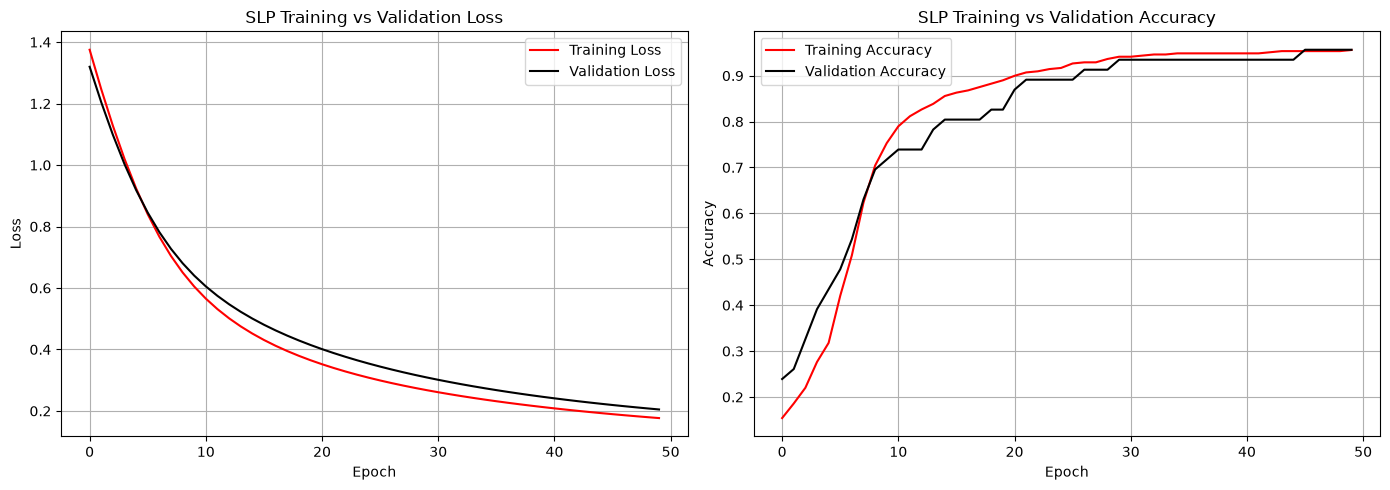

Test Loss: 0.196
Test Accuracy: 0.9298
Test Accuracy (%): 92.98

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.90      0.90      0.90        42
      Benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



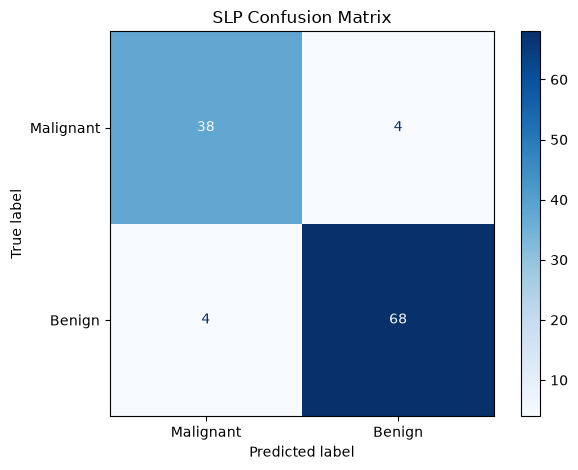

SLP Model Limitations
1. SLP has only one output layer.
2. It can learn only linear decision boundaries.
3. It cannot easily learn complex patterns.
4. Its performance depends on data quality and features.
5. It may perform worse than a deeper neural network on complex data.

Conclusion:
SLP provides a simple baseline for breast cancer classification.
We can compare it with a Multi-Layer Perceptron (MLP).


In [90]:
# Task - (2)

# Build the Single-Layer Perceptron - [2.1]

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Create SLP model
model_slp = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(1, activation="sigmoid")
])

# Display model architecture
model_slp.summary()

# Compile the SLP Model - [2.2]

model_slp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("SLP Model Compiled Successfully!")

# Display model summary
model_slp.summary()

# Train the SLP Model - [2.3]

history_slp = model_slp.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("SLP Model Training Completed")

# Plot SLP Training Curves - [2.4]

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training vs Validation Loss
axes[0].plot(
    history_slp.history["loss"],
    color="red",
    label="Training Loss"
)

axes[0].plot(
    history_slp.history["val_loss"],
    color="black",
    label="Validation Loss"
)

axes[0].set_title("SLP Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Training vs Validation Accuracy
axes[1].plot(
    history_slp.history["accuracy"],
    color="red",
    label="Training Accuracy"
)

axes[1].plot(
    history_slp.history["val_accuracy"],
    color="black",
    label="Validation Accuracy"
)

axes[1].set_title("SLP Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("SLP_training_curves.png", dpi=150)
plt.show()

# Evaluate the SLP Model - [2.5]

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Evaluate model on test data
test_loss, test_accuracy = model_slp.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2))

# Predict test data
y_pred_prob = model_slp.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_pred_slp = (y_pred_prob >= 0.5).astype(int)

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_slp,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_slp,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SLP Confusion Matrix")
plt.tight_layout()
plt.savefig("SLP_confusion_matrix.png", dpi=150)
plt.show()

# Limitations of Single-Layer Perceptron - [2.6]

print("SLP Model Limitations")

print("1. SLP has only one output layer.")
print("2. It can learn only linear decision boundaries.")
print("3. It cannot easily learn complex patterns.")
print("4. Its performance depends on data quality and features.")
print("5. It may perform worse than a deeper neural network on complex data.")

print("\nConclusion:")
print("SLP provides a simple baseline for breast cancer classification.")
print("We can compare it with a Multi-Layer Perceptron (MLP).")

In [91]:
# Task - (3)

# Build MLP Model (ReLU)  - [3.1]

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model_mlp = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

print("MLP Model Architecture:")
model_mlp.summary()

print("\nTotal Trainable Parameters:",
      model_mlp.count_params())



MLP Model Architecture:


Model: "sequential_54"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_144 (Dense)                    │ (None, 64)                  │           1,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_145 (Dense)                    │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_146 (Dense)                    │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)


Total Trainable Parameters: 4097


## Why Do We Need Hidden Layers in an MLP?

Hidden layers help a neural network learn complex and non-linear relationships in data.

- **First hidden layer (64 neurons):** Learns basic patterns and relationships from the input features.
- **Second hidden layer (32 neurons):** Combines learned patterns to identify more complex relationships.
- **ReLU activation:** Introduces non-linearity, allowing the model to learn patterns that a simple linear model cannot represent.
- **Output layer (Sigmoid):** Produces a probability between 0 and 1 for binary classification.

### Why not use only one layer?

A single-layer model is limited in the decision boundaries it can learn. Multiple hidden layers allow the network to learn hierarchical features and more complex patterns.

The Universal Approximation Theorem shows that a sufficiently wide network with a suitable non-linear activation can approximate many continuous functions. However, it does not guarantee that a model will learn the correct function or achieve high accuracy.

**Conclusion:** Hidden layers increase the learning capacity of an MLP, but adding more layers also increases computational cost and may lead to overfitting.

In [92]:
# Compile and Train MLP (ReLU) - [3.3]

# Compile the model
model_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("MLP Model Compiled Successfully!")

# Train the model
history_mlp = model_mlp.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("\nMLP Model Training Completed")

MLP Model Compiled Successfully!
Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9193 - loss: 0.4293 - val_accuracy: 0.9348 - val_loss: 0.3171
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9584 - loss: 0.2521 - val_accuracy: 0.9565 - val_loss: 0.2174
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9682 - loss: 0.1630 - val_accuracy: 0.9565 - val_loss: 0.1655
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9731 - loss: 0.1183 - val_accuracy: 0.9565 - val_loss: 0.1331
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9731 - loss: 0.0936 - val_accuracy: 0.9783 - val_loss: 0.1097
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.0784 - val_accuracy: 0.9783 - val_loss: 0.0923
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9804 - loss: 0.0684 - val_accuracy: 0.9783 - val_loss: 0.0802
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss:

ReLU Model Training Completed!
Tanh Model Training Completed!
Sigmoid Model Training Completed!


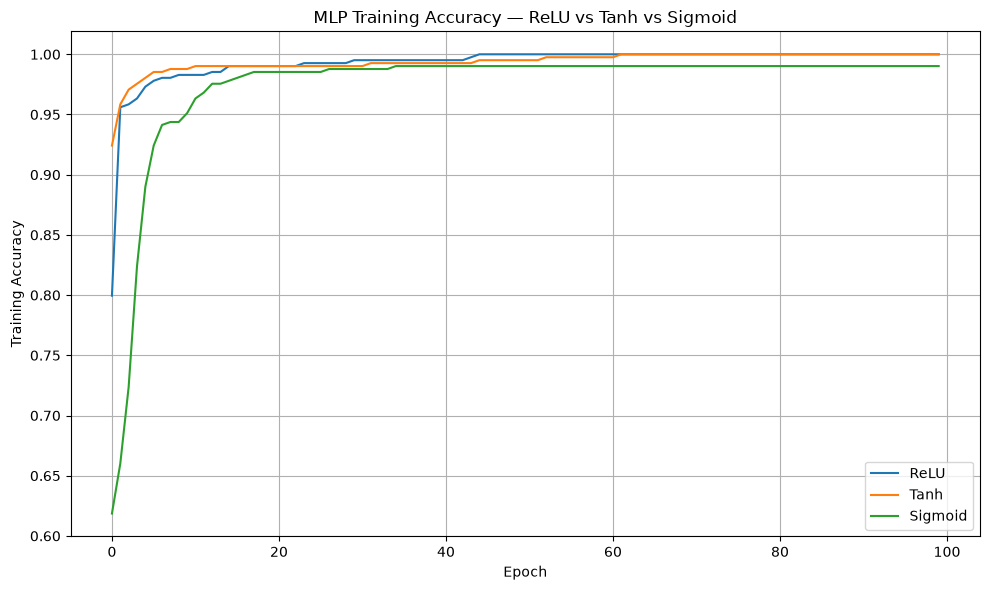


Activation Function Comparison:
Activation  Final Training Accuracy  Final Validation Accuracy
      ReLU                   1.0000                     1.0000
      Tanh                   1.0000                     0.9565
   Sigmoid                   0.9902                     0.9783

 3.4 Completed!


In [93]:
# Compare ReLU, Tanh and Sigmoid Activation Functions - [3.4]

import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Function to build an MLP model
def build_mlp(activation_name):
    model = keras.Sequential([
        keras.Input(shape=(30,)),
        layers.Dense(64, activation=activation_name),
        layers.Dense(32, activation=activation_name),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Model 1: ReLU

tf.keras.utils.set_random_seed(42)

model_relu = build_mlp("relu")

history_relu = model_relu.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)

print("ReLU Model Training Completed!")


# Model 2: Tanh

tf.keras.utils.set_random_seed(42)

model_tanh = build_mlp("tanh")

history_tanh = model_tanh.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)

print("Tanh Model Training Completed!")



# Model 3: Sigmoid

tf.keras.utils.set_random_seed(42)

model_sigmoid = build_mlp("sigmoid")

history_sigmoid = model_sigmoid.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    verbose=0
)

print("Sigmoid Model Training Completed!")


# Plot Training Accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    history_relu.history["accuracy"],
    label="ReLU"
)

plt.plot(
    history_tanh.history["accuracy"],
    label="Tanh"
)

plt.plot(
    history_sigmoid.history["accuracy"],
    label="Sigmoid"
)

plt.title("MLP Training Accuracy — ReLU vs Tanh vs Sigmoid")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("MLP_Activation_Comparison.png", dpi=150)
plt.show()


# Create Comparison Table

activation_results = pd.DataFrame({
    "Activation": ["ReLU", "Tanh", "Sigmoid"],
    "Final Training Accuracy": [
        history_relu.history["accuracy"][-1],
        history_tanh.history["accuracy"][-1],
        history_sigmoid.history["accuracy"][-1]
    ],
    "Final Validation Accuracy": [
        history_relu.history["val_accuracy"][-1],
        history_tanh.history["val_accuracy"][-1],
        history_sigmoid.history["val_accuracy"][-1]
    ]
})

print("\nActivation Function Comparison:")
print(activation_results.round(4).to_string(index=False))

print("\n 3.4 Completed!")

## Activation Functions in MLP - [3.5]

Activation functions help neural networks learn non-linear relationships in data.

### 1. ReLU (Rectified Linear Unit)
- Formula: \(f(x) = \max(0,x)\)
- Output: Zero for negative inputs and the input itself for positive inputs.
- Advantage: Simple, computationally efficient, and commonly used in hidden layers.
- Limitation: Some neurons may stop learning if they consistently output zero.

### 2. Tanh (Hyperbolic Tangent)
- Output range: -1 to 1.
- Advantage: Produces zero-centered outputs.
- Limitation: Can suffer from vanishing gradients for very large positive or negative inputs.

### 3. Sigmoid
- Formula: \(f(x) = \frac{1}{1+e^{-x}}\)
- Output range: 0 to 1.
- Advantage: Useful in the output layer for binary classification because it produces probabilities.
- Limitation: Can suffer from vanishing gradients when used in hidden layers.

### Comparison and Conclusion

ReLU is a common choice for hidden layers, while Sigmoid is commonly used in the output layer for binary classification. Tanh is another possible hidden-layer activation.

The best activation function for this dataset should be selected using validation performance and final test results, rather than training accuracy alone.

Best Activation Function: ReLU
Best Validation Accuracy: 1.0

BEST MLP CLASSIFICATION REPORT
--------------------------------
              precision    recall  f1-score   support

   Malignant       0.93      0.98      0.95        42
      Benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114


SLP vs MLP Comparison
     Model  Accuracy  Precision  Recall  F1 Score
       SLP    0.9298     0.9444  0.9444    0.9444
MLP (ReLU)    0.9649     0.9857  0.9583    0.9718


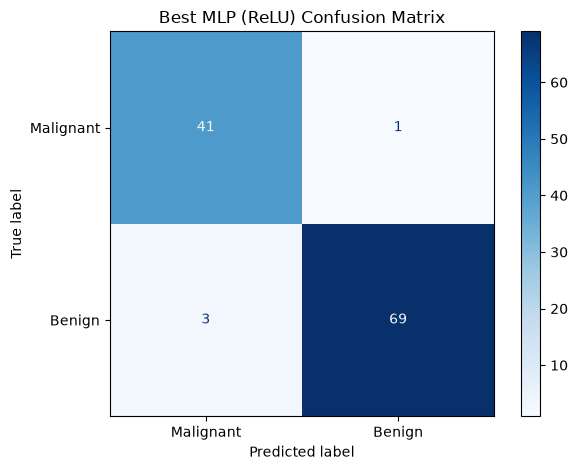

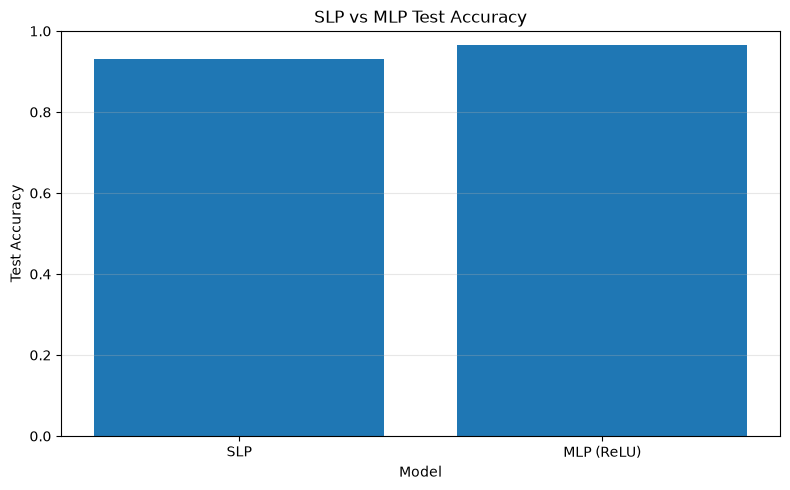


Task 3 Completed Successfully


In [94]:
# Evaluate MLP and Compare with SLP - [3.6]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Select the best activation model

models = {
    "ReLU": model_relu,
    "Tanh": model_tanh,
    "Sigmoid": model_sigmoid
}

validation_accuracies = {
    "ReLU": max(history_relu.history["val_accuracy"]),
    "Tanh": max(history_tanh.history["val_accuracy"]),
    "Sigmoid": max(history_sigmoid.history["val_accuracy"])
}

best_activation = max(validation_accuracies, key=validation_accuracies.get)
best_mlp = models[best_activation]

print("Best Activation Function:", best_activation)
print("Best Validation Accuracy:",
      round(validation_accuracies[best_activation], 4))

# 2. Evaluate SLP

y_pred_slp_prob = model_slp.predict(X_test_scaled, verbose=0).ravel()
y_pred_slp_final = (y_pred_slp_prob >= 0.5).astype(int)


# 3. Evaluate Best MLP

mlp_test_loss, mlp_test_accuracy = best_mlp.evaluate(
    X_test_scaled, y_test, verbose=0
)

y_pred_mlp_prob = best_mlp.predict(X_test_scaled, verbose=0).ravel()
y_pred_mlp_final = (y_pred_mlp_prob >= 0.5).astype(int)


# 4. Classification Reports

print("\nBEST MLP CLASSIFICATION REPORT")
print("--------------------------------")

print(classification_report(
    y_test,
    y_pred_mlp_final,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    zero_division=0
))

# 5. Model Comparison Table

def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

comparison = pd.DataFrame([
    {
        "Model": "SLP",
        **get_metrics(y_test, y_pred_slp_final)
    },
    {
        "Model": f"MLP ({best_activation})",
        **get_metrics(y_test, y_pred_mlp_final)
    }
])

print("\nSLP vs MLP Comparison")
print(comparison.round(4).to_string(index=False))

# 6. Plot Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred_mlp_final,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Best MLP ({best_activation}) Confusion Matrix")
plt.tight_layout()
plt.savefig("MLP_confusion_matrix.png", dpi=150)
plt.show()


# 7. Plot SLP vs MLP Accuracy

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("SLP vs MLP Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("SLP_vs_MLP_Comparison.png", dpi=150)
plt.show()

print("\nTask 3 Completed Successfully")

In [95]:
# Task - (4)
# Build MLP for Early Stopping Experiment - [4.1]

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build a fresh MLP model
model_early = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Compile the model
model_early.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
print("Early Stopping Experiment Model:")
model_early.summary()

# Train for 300 epochs without Early Stopping
history_early = model_early.fit(
    X_train_scaled,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("\n 4.1 Training Completed")

Early Stopping Experiment Model:


Model: "sequential_58"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_156 (Dense)                    │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_157 (Dense)                    │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_158 (Dense)                    │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8753 - loss: 0.4476 - val_accuracy: 0.8913 - val_loss: 0.3377
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9511 - loss: 0.1975 - val_accuracy: 0.9130 - val_loss: 0.2122
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9682 - loss: 0.1129 - val_accuracy: 0.9348 - val_loss: 0.1521
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9804 - loss: 0.0796 - val_accuracy: 0.9565 - val_loss: 0.1110
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.0653 - val_accuracy: 0.9783 - val_loss: 0.0891
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9853 - loss: 0.0573 - val_accuracy: 0.9783 - val_loss: 0.0792
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.0511 - val_accuracy: 0.9783 - val_loss: 0.0728
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.0459 - val_accuracy: 0.9783 - 

In [96]:
# Add EarlyStopping Callback - [4.2]

from tensorflow.keras.callbacks import EarlyStopping

# Create EarlyStopping callback
es = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

# Build a fresh MLP model
model_es = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Compile model
model_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train with EarlyStopping
history_es = model_es.fit(
    X_train_scaled,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es],
    verbose=1
)

print("\nTask 4.2 Completed Successfully!")
print("Epochs actually trained:", len(history_es.history["loss"]))
print("Best validation loss:", round(min(history_es.history["val_loss"]), 4))

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8826 - loss: 0.3511 - val_accuracy: 0.9565 - val_loss: 0.2719
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9609 - loss: 0.1592 - val_accuracy: 0.9130 - val_loss: 0.1817
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9731 - loss: 0.1039 - val_accuracy: 0.9565 - val_loss: 0.1297
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0788 - val_accuracy: 0.9565 - val_loss: 0.0962
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.0661 - val_accuracy: 0.9783 - val_loss: 0.0794
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9878 - loss: 0.0576 - val_accuracy: 0.9783 - val_loss: 0.0689
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9902 - loss: 0.0510 - val_accuracy: 0.9783 - val_loss: 0.0613
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9902 - loss: 0.0458 - val_accuracy: 0.9783 - 

# WHY Early Stopping (Markdown) - [4.3]

## Why Early Stopping?

Early Stopping is a regularization technique used to prevent overfitting in neural networks. It monitors the model's validation performance and stops training when improvement stops.

### 1. `monitor='val_loss'`
This parameter monitors validation loss instead of training loss. Training loss may continue to decrease even when the model starts overfitting. Validation loss helps us understand how well the model generalizes to unseen data.

### 2. `patience=15`
This allows 15 consecutive epochs without improvement in validation loss before training stops. It prevents the model from stopping too early because of a temporary plateau or small fluctuation.

### 3. `restore_best_weights=True`
After training stops, this restores the model weights from the epoch with the lowest validation loss. Without this option, the model generally keeps the weights from the final epoch, which may perform worse if overfitting occurred afterward.

### 4. `verbose=1`
This displays messages during training, including when Early Stopping stops the training and when the best weights are restored.

### Conclusion
Early Stopping can reduce unnecessary training time and help prevent overfitting by selecting weights based on validation performance. It does not guarantee that overfitting will always be eliminated.

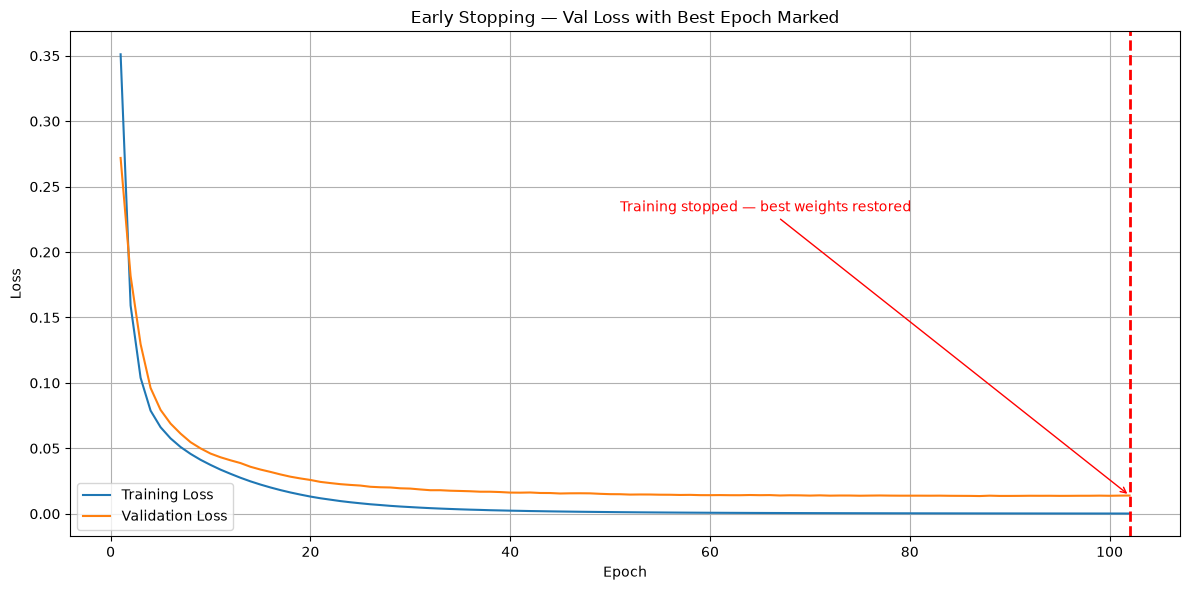

Epochs actually completed: 102
Best validation loss: 0.0136
Task 4.4 Completed Successfully


In [97]:
# Plot Early Stopping Curves - [4.4]

import matplotlib.pyplot as plt

# Get training and validation loss
train_loss = history_es.history["loss"]
val_loss = history_es.history["val_loss"]

# Number of epochs actually completed
stopped_epoch = len(train_loss)

# Create plot
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, stopped_epoch + 1),
    train_loss,
    label="Training Loss"
)

plt.plot(
    range(1, stopped_epoch + 1),
    val_loss,
    label="Validation Loss"
)

# Mark the stopping epoch with a vertical red dashed line
plt.axvline(
    x=stopped_epoch,
    color="red",
    linestyle="--",
    linewidth=2
)

# Annotate the stopping line
plt.annotate(
    "Training stopped — best weights restored",
    xy=(stopped_epoch, val_loss[-1]),
    xytext=(stopped_epoch * 0.5, max(val_loss) * 0.85),
    arrowprops=dict(arrowstyle="->", color="red"),
    color="red",
    fontsize=10
)

plt.title("Early Stopping — Val Loss with Best Epoch Marked")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("Early_Stopping_Curves.png", dpi=150)
plt.show()

print("Epochs actually completed:", stopped_epoch)
print("Best validation loss:", round(min(val_loss), 4))
print("Task 4.4 Completed Successfully")

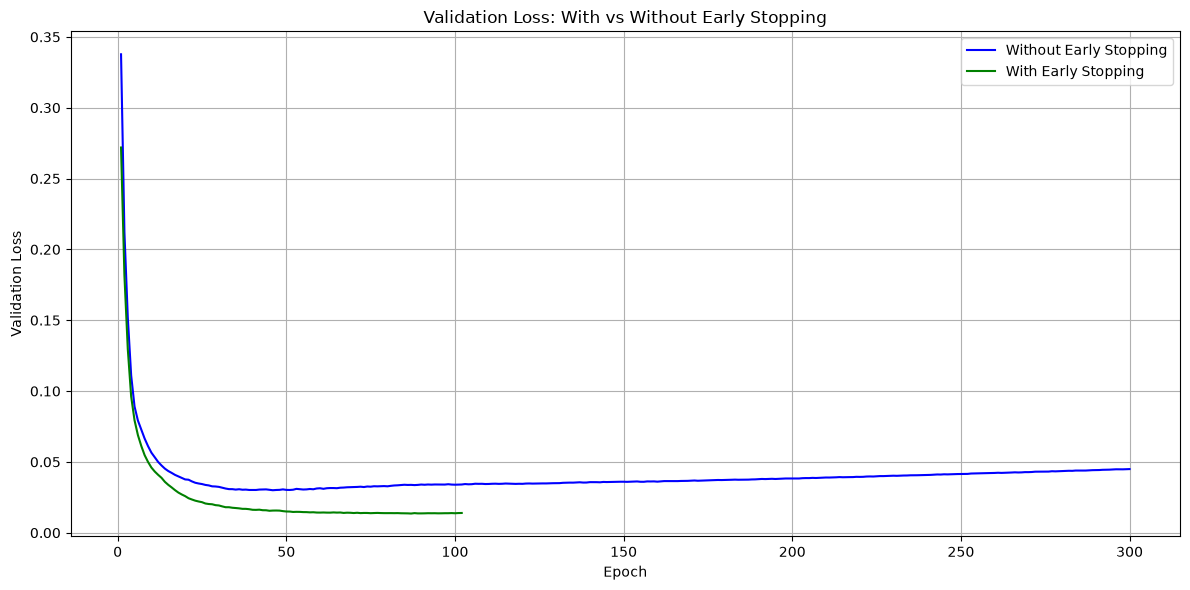

WITHOUT Early Stopping
Epochs trained: 300
Best validation-loss epoch: 46
Best validation loss: 0.03

WITH Early Stopping
Epochs trained: 102
Best validation-loss epoch: 87
Best validation loss: 0.0136

Validation loss first rises after its previous epoch at epoch: 47
Inspect the curve after epoch 46 to identify the overfitting trend.

FINAL MODEL COMPARISON
                 Model  Epochs Trained  Best Validation Loss  Test Loss  Test Accuracy
Without Early Stopping             300                0.0300     0.2487         0.9737
   With Early Stopping             102                0.0136     0.1889         0.9561

Test accuracy comparison:
Without Early Stopping: 97.37 %
With Early Stopping: 95.61 %
The model without Early Stopping achieved higher test accuracy.
Early Stopping achieved lower best validation loss.

Task 4.5 Completed Successfully


In [98]:
# Task 4.5: Compare With vs Without Early Stopping

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# 1. Plot validation loss curves

val_loss_without = history_early.history["val_loss"]
val_loss_with = history_es.history["val_loss"]

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(val_loss_without) + 1),
    val_loss_without,
    label="Without Early Stopping",
    color="blue"
)

plt.plot(
    range(1, len(val_loss_with) + 1),
    val_loss_with,
    label="With Early Stopping",
    color="green"
)

plt.title("Validation Loss: With vs Without Early Stopping")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("With_vs_Without_EarlyStopping.png", dpi=150)
plt.show()


# 2. Find best validation-loss epochs

best_epoch_without = val_loss_without.index(min(val_loss_without)) + 1
best_epoch_with = val_loss_with.index(min(val_loss_with)) + 1

best_val_without = min(val_loss_without)
best_val_with = min(val_loss_with)

print("WITHOUT Early Stopping")
print("Epochs trained:", len(val_loss_without))
print("Best validation-loss epoch:", best_epoch_without)
print("Best validation loss:", round(best_val_without, 4))

print("\nWITH Early Stopping")
print("Epochs trained:", len(val_loss_with))
print("Best validation-loss epoch:", best_epoch_with)
print("Best validation loss:", round(best_val_with, 4))


# 3. Check when validation loss starts rising

# Find the lowest validation loss, then inspect subsequent epochs.
rising_epochs = []

for i in range(best_epoch_without, len(val_loss_without)):
    if val_loss_without[i] > val_loss_without[i - 1]:
        rising_epochs.append(i + 1)

if rising_epochs:
    print(
        "\nValidation loss first rises after its previous epoch at epoch:",
        rising_epochs[0]
    )
    print(
        "Inspect the curve after epoch",
        best_epoch_without,
        "to identify the overfitting trend."
    )
else:
    print(
        "\nNo rise after the minimum validation loss was detected."
    )


# 4. Evaluate both models on test set

# Without Early Stopping
test_loss_without, test_acc_without = model_early.evaluate(
    X_test_scaled, y_test, verbose=0
)

# With Early Stopping (best weights restored)
test_loss_with, test_acc_with = model_es.evaluate(
    X_test_scaled, y_test, verbose=0
)

# 5. Comparison table

comparison_df = pd.DataFrame({
    "Model": [
        "Without Early Stopping",
        "With Early Stopping"
    ],
    "Epochs Trained": [
        len(history_early.history["loss"]),
        len(history_es.history["loss"])
    ],
    "Best Validation Loss": [
        best_val_without,
        best_val_with
    ],
    "Test Loss": [
        test_loss_without,
        test_loss_with
    ],
    "Test Accuracy": [
        test_acc_without,
        test_acc_with
    ]
})

print("\nFINAL MODEL COMPARISON")
print(comparison_df.round(4).to_string(index=False))

print("\nTest accuracy comparison:")
print("Without Early Stopping:", round(test_acc_without * 100, 2), "%")
print("With Early Stopping:", round(test_acc_with * 100, 2), "%")

if test_acc_with > test_acc_without:
    print("Early Stopping achieved higher test accuracy.")
elif test_acc_with < test_acc_without:
    print("The model without Early Stopping achieved higher test accuracy.")
else:
    print("Both models achieved the same test accuracy.")

if best_val_with < best_val_without:
    print("Early Stopping achieved lower best validation loss.")
elif best_val_with > best_val_without:
    print("The model without Early Stopping achieved lower best validation loss.")
else:
    print("Both models achieved the same best validation loss.")

print("\nTask 4.5 Completed Successfully")

# Markdown cell for comparison  

## Comparison: With vs Without Early Stopping

Two identical MLP models were compared using validation loss and test accuracy.

### 1. Model without Early Stopping
This model was trained for up to 300 epochs without an EarlyStopping callback. Overfitting may begin when training loss continues to decrease while validation loss starts rising. The epoch range should be identified from the plotted validation-loss curve and the printed results.

### 2. Model with Early Stopping
This model monitored validation loss with `patience=15`. Training stopped when validation loss failed to improve for the specified patience period, and `restore_best_weights=True` restored the weights from the best validation-loss epoch.

### 3. Validation Loss Comparison
The two validation-loss curves show how each model performed during training. Compare their minimum validation losses and inspect the no-callback curve for a sustained increase after its minimum.

### 4. Test Accuracy Comparison
Both models were evaluated on the same test dataset. The printed comparison table reports test loss and test accuracy for each model.

### Conclusion
Early Stopping can reduce unnecessary training and help limit overfitting. The actual winner must be determined from the measured validation loss and test accuracy; Early Stopping does not guarantee higher test accuracy in every experiment.

In [99]:
# Task - (5)

# Build MLP with Dropout - [5.1]

from tensorflow import keras
from tensorflow.keras import layers

model_drop = keras.Sequential([
    keras.Input(shape=(30,)),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation='sigmoid')
])

# Print model architecture
model_drop.summary()

Model: "sequential_60"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_162 (Dense)                    │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_28 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_163 (Dense)                    │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_29 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_164 (Dense)                    │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

###### WHY Dropout — Markdown Cell - [5.2]

### Why Dropout?

Dropout(rate=0.3) randomly sets 30% of neuron activations to zero during each training batch. This helps reduce overfitting by preventing the network from relying too heavily on specific neurons.

It encourages the network to learn redundant representations, distributing knowledge across many neurons instead of depending on a single neuron.

At inference time, such as during `model.predict()`, Dropout is automatically disabled, and all neurons contribute to the prediction. During training, the remaining activations are scaled appropriately to maintain their expected magnitude.

Dropout can be understood as approximately training an ensemble of many thinned neural networks that share weights. This helps reduce variance and improve generalisation to unseen data.

In [100]:
# Train with Dropout + Early Stopping - [5.3]

from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping

# Compile the model
model_drop.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping callback
es_drop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history_drop = model_drop.fit(
    X_train_scaled,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_drop],
    verbose=1
)

print("Dropout model training completed!")

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7922 - loss: 0.4991 - val_accuracy: 0.9565 - val_loss: 0.2939
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9535 - loss: 0.2250 - val_accuracy: 0.9565 - val_loss: 0.1861
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9560 - loss: 0.1529 - val_accuracy: 0.9783 - val_loss: 0.1389
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9682 - loss: 0.1143 - val_accuracy: 0.9783 - val_loss: 0.1068
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9731 - loss: 0.0892 - val_accuracy: 0.9783 - val_loss: 0.0840
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9731 - loss: 0.0754 - val_accuracy: 0.9783 - val_loss: 0.0692
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9731 - loss: 0.0679 - val_accuracy: 0.9783 - val_loss: 0.0623
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0736 - val_accuracy: 0.9783 - 

In [ ]:
# Train models with Dropout 0.1 and 0.5 - [5.4]


# Compare Dropout Rates 0.1, 0.3, and 0.5

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Early Stopping callback
def get_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

# Model with Dropout 0.1
model_drop_01 = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(1, activation="sigmoid")
])

model_drop_01.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_drop_01 = model_drop_01.fit(
    X_train_scaled, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[get_early_stopping()],
    verbose=1
)

# Model with Dropout 0.5
model_drop_05 = keras.Sequential([
    keras.Input(shape=(30,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model_drop_05.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_drop_05 = model_drop_05.fit(
    X_train_scaled, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[get_early_stopping()],
    verbose=1
)

print("Dropout 0.1, 0.3, and 0.5 models are ready for comparison.")

# Plot validation accuracy for all three rates


# Plot validation accuracy comparison

plt.figure(figsize=(12, 6))

plt.plot(
    history_drop_01.history["val_accuracy"],
    label="Dropout 0.1"
)

plt.plot(
    history_drop.history["val_accuracy"],
    label="Dropout 0.3"
)

plt.plot(
    history_drop_05.history["val_accuracy"],
    label="Dropout 0.5"
)

plt.title("Dropout Rate Comparison — Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("Dropout_Rate_Comparison.png", dpi=150)
plt.show()


Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8875 - loss: 0.4002 - val_accuracy: 0.8696 - val_loss: 0.2799
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9438 - loss: 0.1889 - val_accuracy: 0.9348 - val_loss: 0.1807
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9633 - loss: 0.1158 - val_accuracy: 0.9565 - val_loss: 0.1279
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9731 - loss: 0.0904 - val_accuracy: 0.9565 - val_loss: 0.0930
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.0729 - val_accuracy: 0.9565 - val_loss: 0.0739
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0636 - val_accuracy: 0.9783 - val_loss: 0.0617
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0564 - val_accuracy: 1.0000 - val_loss: 0.0531
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0521 - val_accuracy: 1.0000 - 

# Markdown cell

## Effect of Dropout Rate

Dropout rate controls the percentage of neuron activations randomly set to zero during training.

- **Dropout 0.1:** Only 10% of activations are dropped. This provides weaker regularisation and may not sufficiently prevent overfitting.
- **Dropout 0.3:** Drops 30% of activations and can provide a useful balance between regularisation and learning.
- **Dropout 0.5:** Drops 50% of activations. This stronger regularisation can slow learning and may cause underfitting if the network cannot learn enough useful patterns.

**Conclusion:** A low dropout rate may allow overfitting, while a high rate may make learning more difficult. The best rate should be selected by comparing validation accuracy and validation loss rather than assuming one rate is always best.

In [ ]:

# Evaluate Dropout Models - [5.5]

import pandas as pd

dropout_models = {
    0.1: (model_drop_01, history_drop_01),
    0.3: (model_drop, history_drop),
    0.5: (model_drop_05, history_drop_05)
}

# Select best rate based on maximum validation accuracy
best_rate = max(
    dropout_models,
    key=lambda rate: max(dropout_models[rate][1].history["val_accuracy"])
)

best_drop_model, best_drop_history = dropout_models[best_rate]

# Evaluate on test data
test_loss, test_accuracy = best_drop_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print("Best Dropout Rate:", best_rate)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Add the best Dropout model to a results table
dropout_result = pd.DataFrame([{
    "Model": f"MLP with Dropout {best_rate}",
    "Best Validation Accuracy": max(
        best_drop_history.history["val_accuracy"]
    ),
    "Test Loss": test_loss,
    "Test Accuracy": test_accuracy
}])

print("\nDropout Model Results:")
print(dropout_result.round(4).to_string(index=False))

# Compare training and validation accuracy


# Compare MLP without Dropout vs MLP with Dropout

normal_train_acc = history_mlp.history["accuracy"][-1]
normal_val_acc = history_mlp.history["val_accuracy"][-1]

drop_train_acc = best_drop_history.history["accuracy"][-1]
drop_val_acc = best_drop_history.history["val_accuracy"][-1]

comparison = pd.DataFrame({
    "Model": ["MLP without Dropout", f"MLP with Dropout {best_rate}"],
    "Training Accuracy": [normal_train_acc, drop_train_acc],
    "Validation Accuracy": [normal_val_acc, drop_val_acc],
    "Accuracy Gap": [
        abs(normal_train_acc - normal_val_acc),
        abs(drop_train_acc - drop_val_acc)
    ]
})

print(comparison.round(4).to_string(index=False))

# Plot comparison
plt.figure(figsize=(10, 6))

labels = ["Without Dropout", "With Dropout"]
train_values = [normal_train_acc, drop_train_acc]
val_values = [normal_val_acc, drop_val_acc]

x = range(len(labels))
width = 0.35

plt.bar(
    [i - width / 2 for i in x],
    train_values,
    width,
    label="Training Accuracy"
)
plt.bar(
    [i + width / 2 for i in x],
    val_values,
    width,
    label="Validation Accuracy"
)

plt.xticks(list(x), labels)
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy — With vs Without Dropout")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("Dropout_Accuracy_Comparison.png", dpi=150)
plt.show()

normal_gap = abs(normal_train_acc - normal_val_acc)
drop_gap = abs(drop_train_acc - drop_val_acc)

if drop_gap < normal_gap:
    print("Dropout produced a smaller training-validation accuracy gap.")
elif drop_gap > normal_gap:
    print("Dropout produced a larger training-validation accuracy gap.")
else:
    print("Both models have the same training-validation accuracy gap.")



In [77]:
# Task - (6)  Regularization (L1, L2, L1-L2)


# MLP with L2 Regularization - [6.1]

from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

# Build model with L2 regularization
model_l2 = keras.Sequential([
    keras.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile model
model_l2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
es_l2 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train model
history_l2 = model_l2.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_l2],
    verbose=1
)

# Display model architecture
model_l2.summary()

print("L2 Regularization model training completed!")



Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8680 - loss: 0.5423 - val_accuracy: 0.8913 - val_loss: 0.4370
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9511 - loss: 0.3124 - val_accuracy: 0.9130 - val_loss: 0.3412
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9609 - loss: 0.2439 - val_accuracy: 0.9348 - val_loss: 0.2848
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9804 - loss: 0.2126 - val_accuracy: 0.9348 - val_loss: 0.2472
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.1956 - val_accuracy: 0.9565 - val_loss: 0.2238
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.1835 - val_accuracy: 0.9565 - val_loss: 0.2087
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9853 - loss: 0.1732 - val_accuracy: 0.9565 - val_loss: 0.1972
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9853 - loss: 0.1640 - val_accuracy: 0.9565 - 

Model: "sequential_44"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_118 (Dense)                    │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_119 (Dense)                    │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_120 (Dense)                    │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 36,869 (144.02 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,580 (96.02 KB)

L2 Regularization model training completed!


# WHY L2 Regularization (Markdown Cell) - [6.2]

## Why L2 Regularization?

L2 regularization adds a penalty term, λ × Σw², to the loss function during training. This penalises large weight values and encourages the model to keep its weights small, although weights are not generally forced to become exactly zero.

By discouraging excessively large weights, L2 regularization can produce a smoother decision boundary. The model relies on many smaller weights instead of depending too heavily on a few dominant weights, which can reduce variance and help prevent overfitting.

In this project, λ = 0.001 is the regularization strength. If λ is too large, the weights may be constrained too strongly, causing underfitting and reducing the model's ability to learn important patterns.

**Conclusion:** L2 regularization helps control model complexity and improve generalisation to unseen data.

In [78]:

# MLP with L1 Regularization - [6.3]

from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

# Build L1 regularized model
model_l1 = keras.Sequential([
    keras.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l1(0.001)
    ),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l1(0.001)
    ),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile model
model_l1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
es_l1 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train model
history_l1 = model_l1.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_l1],
    verbose=1
)

# Display model summary
model_l1.summary()

print("L1 Regularization model training completed!")


Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8729 - loss: 1.5214 - val_accuracy: 0.9130 - val_loss: 1.3430
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9658 - loss: 1.2361 - val_accuracy: 0.9348 - val_loss: 1.1928
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9707 - loss: 1.1006 - val_accuracy: 0.9348 - val_loss: 1.0994
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9756 - loss: 1.0132 - val_accuracy: 0.9565 - val_loss: 1.0152
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9829 - loss: 0.9390 - val_accuracy: 0.9565 - val_loss: 0.9348
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9853 - loss: 0.8701 - val_accuracy: 0.9565 - val_loss: 0.8631
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.8045 - val_accuracy: 0.9565 - val_loss: 0.7974
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.7422 - val_accuracy: 0.9783 - 

Model: "sequential_45"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_121 (Dense)                    │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_122 (Dense)                    │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_123 (Dense)                    │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 36,869 (144.02 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,580 (96.02 KB)

L1 Regularization model training completed!


In [79]:
# MLP with L1-L2 (ElasticNet) Regularization - [6.4]

from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

# Build L1-L2 model
model_l1l2 = keras.Sequential([
    keras.Input(shape=(30,)),

    keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l1_l2(
            l1=0.0001,
            l2=0.001
        )
    ),

    keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l1_l2(
            l1=0.0001,
            l2=0.001
        )
    ),

    keras.layers.Dense(1, activation="sigmoid")
])

# Compile model
model_l1l2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
es_l1l2 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train model
history_l1l2 = model_l1l2.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[es_l1l2],
    verbose=1
)

# Display model summary
model_l1l2.summary()

print("L1-L2 (ElasticNet) model training completed")


Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8973 - loss: 0.6670 - val_accuracy: 0.9348 - val_loss: 0.5371
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9609 - loss: 0.4158 - val_accuracy: 0.9130 - val_loss: 0.4397
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9658 - loss: 0.3414 - val_accuracy: 0.9348 - val_loss: 0.3829
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.3054 - val_accuracy: 0.9565 - val_loss: 0.3403
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.2852 - val_accuracy: 0.9565 - val_loss: 0.3123
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9829 - loss: 0.2708 - val_accuracy: 0.9565 - val_loss: 0.2939
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.2580 - val_accuracy: 0.9565 - val_loss: 0.2790
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9878 - loss: 0.2464 - val_accuracy: 0.9783 - 

Model: "sequential_46"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_124 (Dense)                    │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_125 (Dense)                    │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_126 (Dense)                    │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 36,869 (144.02 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,580 (96.02 KB)

L1-L2 (ElasticNet) model training completed


## Why L1-L2 (ElasticNet) Regularization?

L1-L2 regularization combines L1 and L2 penalties in the same model. L1 penalises the absolute values of weights and can encourage some weights to become exactly zero, while L2 penalises squared weights and encourages weights to remain small.

In the Breast Cancer dataset, features such as radius, perimeter, and area are highly correlated. L2 regularization can help control large weights across correlated features, while L1 can encourage sparse weights by reducing the influence of less informative patterns.

In this project, the regularization strengths are `l1=0.0001` and `l2=0.001`. These values control the relative contributions of the two penalties.

**Conclusion:** ElasticNet combines the benefits of L1 and L2 regularization, potentially improving model simplicity and generalisation. Its actual performance should be evaluated using validation and test results.

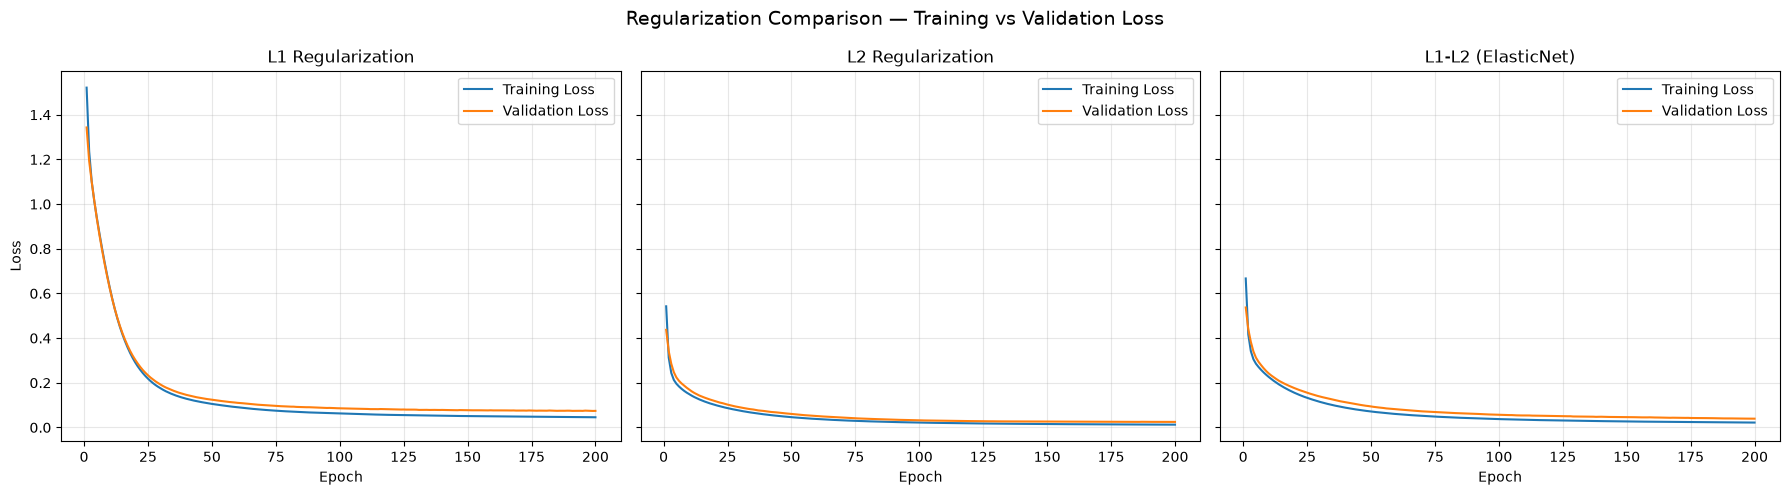

Regularization comparison plot completed!
             Model  Final Training Loss  Final Validation Loss  Final Loss Gap  Best Validation Accuracy  Best Validation Accuracy Epoch
 L1 Regularization               0.0455                 0.0742          0.0286                       1.0                              85
 L2 Regularization               0.0125                 0.0248          0.0123                       1.0                              14
L1-L2 (ElasticNet)               0.0218                 0.0392          0.0174                       1.0                              17

Smallest final train-validation loss gap: L2 Regularization
Best validation accuracy: L1 Regularization


In [80]:
# Regularization Comparison Plot - [6.5]

import matplotlib.pyplot as plt
import numpy as np

# Store training histories
histories = [
    ("L1 Regularization", history_l1),
    ("L2 Regularization", history_l2),
    ("L1-L2 (ElasticNet)", history_l1l2)
]

# Find a common Y-axis range for all three plots
all_losses = []

for name, history in histories:
    all_losses.extend(history.history["loss"])
    all_losses.extend(history.history["val_loss"])

y_min = min(all_losses)
y_max = max(all_losses)
padding = (y_max - y_min) * 0.05

# Create 1x3 subplots with shared Y-axis
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharey=True
)

for ax, (name, history) in zip(axes, histories):
    train_loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs_train = range(1, len(train_loss) + 1)
    epochs_val = range(1, len(val_loss) + 1)

    ax.plot(epochs_train, train_loss, label="Training Loss")
    ax.plot(epochs_val, val_loss, label="Validation Loss")

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Loss")

fig.suptitle(
    "Regularization Comparison — Training vs Validation Loss",
    fontsize=14
)

plt.tight_layout()
plt.savefig("Regularization_Loss_Comparison.png", dpi=150)
plt.show()

print("Regularization comparison plot completed!")


# Calculate the loss gap and best validation accuracy


# Compare regularization results

results = []

for name, history in histories:
    train_loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    val_accuracy = history.history["val_accuracy"]

    # Compare final recorded training and validation loss
    final_gap = abs(train_loss[-1] - val_loss[-1])

    results.append({
        "Model": name,
        "Final Training Loss": train_loss[-1],
        "Final Validation Loss": val_loss[-1],
        "Final Loss Gap": final_gap,
        "Best Validation Accuracy": max(val_accuracy),
        "Best Validation Accuracy Epoch": np.argmax(val_accuracy) + 1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

smallest_gap_model = results_df.loc[
    results_df["Final Loss Gap"].idxmin(), "Model"
]

best_accuracy_model = results_df.loc[
    results_df["Best Validation Accuracy"].idxmax(), "Model"
]

print("\nSmallest final train-validation loss gap:", smallest_gap_model)
print("Best validation accuracy:", best_accuracy_model)



## Regularization Comparison — Results and Discussion

The L1, L2, and L1-L2 regularization models were compared using their training loss, validation loss, and validation accuracy.

- **Smallest train-validation loss gap:** [Enter the model identified by the comparison code].
- **Best validation accuracy:** [Enter the model identified by the comparison code].
- **Comparison with theory:** L1 encourages sparse weights, L2 encourages smaller weights, and L1-L2 combines both penalties. The results may support these theoretical expectations, but no regularizer is guaranteed to perform best on every dataset.

**Conclusion:** The preferred regularizer should provide good validation performance and generalisation, rather than simply achieving the lowest training loss.

TEST PERFORMANCE COMPARISON
            Model  Test Loss  Test Accuracy  Test Accuracy (%)
No Regularization     0.1516         0.9561            95.6140
               L1     0.1498         0.9561            95.6140
               L2     0.1532         0.9386            93.8596
            L1-L2     0.1392         0.9561            95.6140

Results saved to Regularization_Test_Results.csv


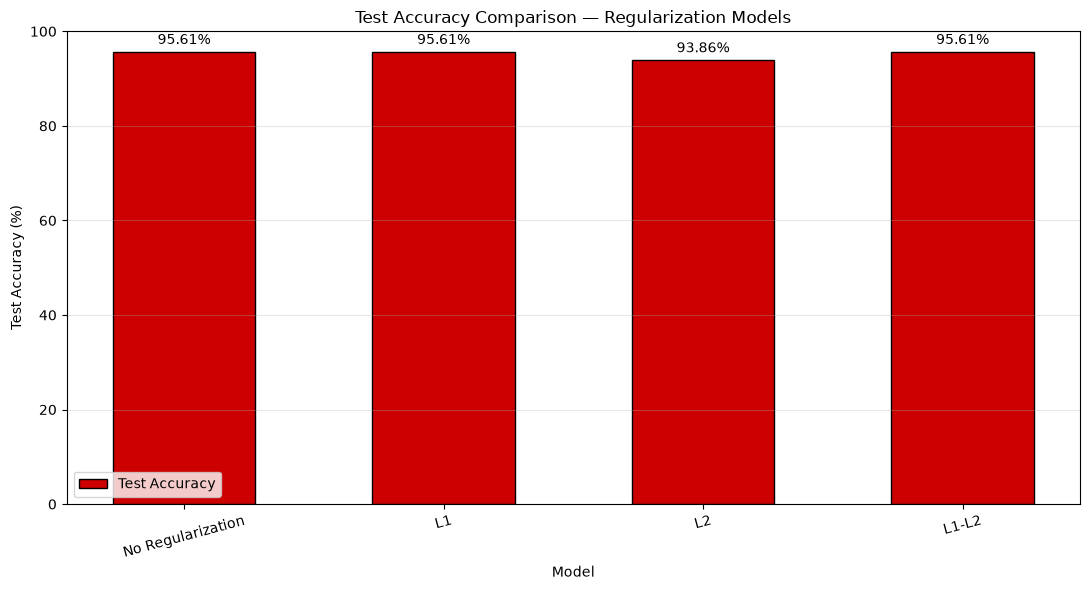


Highest test accuracy: No Regularization (95.61%)


In [81]:

# Evaluate All Regularized Models -  [6.6]

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Task 3 best MLP
# model_mlp was trained in Task 3
models_to_evaluate = {
    "No Regularization": model_mlp,
    "L1": model_l1,
    "L2": model_l2,
    "L1-L2": model_l1l2
}

results = []

for name, model in models_to_evaluate.items():
    test_loss, test_accuracy = model.evaluate(
        X_test_scaled,
        y_test,
        verbose=0
    )

    results.append({
        "Model": name,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy,
        "Test Accuracy (%)": test_accuracy * 100
    })

results_df_66 = pd.DataFrame(results)

print("TEST PERFORMANCE COMPARISON")
print(results_df_66.round(4).to_string(index=False))

# Save results in CSV
results_df_66.to_csv(
    "Regularization_Test_Results.csv",
    index=False
)

print("\nResults saved to Regularization_Test_Results.csv")

# Plot test accuracy comparison


# Grouped bar chart: Test Accuracy

model_names = results_df_66["Model"].tolist()
test_accuracies = results_df_66["Test Accuracy (%)"].tolist()

x = np.arange(len(model_names))
bar_width = 0.55

plt.figure(figsize=(11, 6))

bars = plt.bar(
    x,
    test_accuracies,
    width=bar_width,
    color="#CC0000",
    edgecolor="black",
    label="Test Accuracy"
)

plt.xticks(x, model_names, rotation=15)
plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Test Accuracy Comparison — Regularization Models")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

# Show accuracy values on each bar
for bar, value in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("Regularization_Test_Accuracy.png", dpi=150)
plt.show()

best_idx = results_df_66["Test Accuracy"].idxmax()

print(
    "\nHighest test accuracy:",
    results_df_66.loc[best_idx, "Model"],
    f"({results_df_66.loc[best_idx, 'Test Accuracy (%)']:.2f}%)"
)



## Evaluation of Regularization Models

Four MLP configurations were evaluated on the unseen test dataset:

- No Regularization
- L1 Regularization
- L2 Regularization
- L1-L2 (ElasticNet) Regularization

Their test accuracies were recorded in a results table and visualised using a bar chart.

**Conclusion:** The model with the highest test accuracy performed best on this test set. Regularization can reduce overfitting, but it does not guarantee higher test accuracy in every experiment. The final selection should also consider validation performance and the training-validation gap.

In [75]:
# Task - (7)

# Final Model - Dropout + L2 + Early Stopping -  [7.1]

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

# Build final model
final_model = keras.Sequential([
    keras.Input(shape=(30,)),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

# Compile model
final_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping callback
final_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train final model
history_final = final_model.fit(
    X_train_scaled,
    y_train,
    epochs=300,
    batch_size=32,
    validation_split=0.1,
    callbacks=[final_early_stopping],
    verbose=1
)

# Display model architecture
final_model.summary()

print("\nFinal model training completed!")


# Evaluate final model on unseen test data

final_test_loss, final_test_accuracy = final_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("FINAL MODEL RESULTS")
print("Test Loss:", round(final_test_loss, 4))
print("Test Accuracy:", round(final_test_accuracy * 100, 2), "%")


Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8484 - loss: 0.5561 - val_accuracy: 0.8913 - val_loss: 0.4118
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9462 - loss: 0.3277 - val_accuracy: 0.9130 - val_loss: 0.3215
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9438 - loss: 0.2689 - val_accuracy: 0.9565 - val_loss: 0.2745
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9658 - loss: 0.2223 - val_accuracy: 0.9565 - val_loss: 0.2404
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.2082 - val_accuracy: 0.9565 - val_loss: 0.2200
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9780 - loss: 0.2022 - val_accuracy: 0.9565 - val_loss: 0.2031
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.1883 - val_accuracy: 0.9565 - val_loss: 0.1919
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9731 - loss: 0.1919 - val_accuracy: 0.9565 - 

Model: "sequential_43"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_115 (Dense)                    │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_116 (Dense)                    │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_117 (Dense)                    │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 36,869 (144.02 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 24,580 (96.02 KB)


Final model training completed!
FINAL MODEL RESULTS
Test Loss: 0.1329
Test Accuracy: 95.61 %


In [76]:

import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#  Full Results Comparison Table - [7.2]

# All 6 models
models = [
    {
        "Model": "SLP (Task 2)",
        "Architecture": "Single Dense Layer",
        "Regularization": "None",
        "Dropout Rate": "0",
        "Early Stopping": "No",
        "Estimator": model_slp
    },
    {
        "Model": "MLP-ReLU (Task 3)",
        "Architecture": "Dense(64) + Dense(32)",
        "Regularization": "None",
        "Dropout Rate": "0",
        "Early Stopping": "No",
        "Estimator": model_mlp
    },
    {
        "Model": "MLP + Early Stopping (Task 4)",
        "Architecture": "Dense(128) + Dense(64)",
        "Regularization": "None",
        "Dropout Rate": "0",
        "Early Stopping": "Yes",
        "Estimator": model_es
    },
    {
        "Model": "MLP + Dropout-best (Task 5)",
        "Architecture": "Dense(128) + Dense(64)",
        "Regularization": "None",
        "Dropout Rate": "Best from Task 5",
        "Early Stopping": "Yes",
        "Estimator": model_drop
    },
    {
        "Model": "MLP + L2 (Task 6)",
        "Architecture": "Dense(128) + Dense(64)",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": "0",
        "Early Stopping": "Yes",
        "Estimator": model_l2
    },
    {
        "Model": "Final Combined Model (Task 7.1)",
        "Architecture": "Dense(128) + Dense(64)",
        "Regularization": "L2 (0.001)",
        "Dropout Rate": "0.3",
        "Early Stopping": "Yes",
        "Estimator": final_model
    }
]

# Calculate test metrics for every model
results = []

for item in models:
    model = item["Estimator"]

    # Predict probabilities and convert to binary classes
    y_probability = model.predict(X_test_scaled, verbose=0).ravel()
    y_pred = (y_probability >= 0.5).astype(int)

    results.append({
        "Model": item["Model"],
        "Architecture": item["Architecture"],
        "Regularization": item["Regularization"],
        "Dropout Rate": item["Dropout Rate"],
        "Early Stopping": item["Early Stopping"],
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

# Create DataFrame
df_results = pd.DataFrame(results)

# Display highlighted comparison table
styled_results = (
    df_results.style
    .format({
        "Test Accuracy": "{:.4f}",
        "Test Precision": "{:.4f}",
        "Test Recall": "{:.4f}",
        "Test F1-Score": "{:.4f}"
    })
    .highlight_max(
        subset=["Test Accuracy", "Test F1-Score"],
        color="#ffcccc"
    )
)

display(styled_results)

# Optional: print numeric results without styling
print("\nFull Model Comparison:")
print(df_results.round(4).to_string(index=False))

# Optional: save results to CSV
df_results.to_csv("Full_Model_Results_Comparison.csv", index=False)
print("\nResults saved to Full_Model_Results_Comparison.csv")


,Model,Architecture,Regularization,Dropout Rate,Early Stopping,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,SLP (Task 2),Single Dense Layer,None,0,No,0.9386,0.9710,0.9306,0.9504
1,MLP-ReLU (Task 3),Dense(64) + Dense(32),None,0,No,0.9561,0.9855,0.9444,0.9645
2,MLP + Early Stopping (Task 4),Dense(128) + Dense(64),None,0,Yes,0.9561,0.9855,0.9444,0.9645
3,MLP + Dropout-best (Task 5),Dense(128) + Dense(64),None,Best from Task 5,Yes,0.9561,0.9855,0.9444,0.9645
4,MLP + L2 (Task 6),Dense(128) + Dense(64),L2 (0.001),0,Yes,0.9561,0.9855,0.9444,0.9645
5,Final Combined Model (Task 7.1),Dense(128) + Dense(64),L2 (0.001),0.3,Yes,0.9561,0.9855,0.9444,0.9645



Full Model Comparison:
                          Model           Architecture Regularization     Dropout Rate Early Stopping  Test Accuracy  Test Precision  Test Recall  Test F1-Score
                   SLP (Task 2)     Single Dense Layer           None                0             No         0.9386          0.9710       0.9306         0.9504
              MLP-ReLU (Task 3)  Dense(64) + Dense(32)           None                0             No         0.9561          0.9855       0.9444         0.9645
  MLP + Early Stopping (Task 4) Dense(128) + Dense(64)           None                0            Yes         0.9561          0.9855       0.9444         0.9645
    MLP + Dropout-best (Task 5) Dense(128) + Dense(64)           None Best from Task 5            Yes         0.9561          0.9855       0.9444         0.9645
              MLP + L2 (Task 6) Dense(128) + Dense(64)     L2 (0.001)                0            Yes         0.9561          0.9855       0.9444         0.9645
Final Comb


# Clinical Insight for Medical Diagnosis Support - [7.3]

## 1. Recommended Model for Clinical Decision Support

For this educational project, I would consider the **Final Combined Model (L2 Regularization + Dropout + Early Stopping)** as a candidate for further evaluation. It combines multiple techniques designed to reduce overfitting and improve generalization.

However, the final model should not be selected based on architecture alone. In cancer screening, **Recall for the malignant class is especially important**, because a false negative means a patient with malignant cancer is incorrectly classified as benign.

Before selecting a model, I would compare the malignant-class recall, precision, F1-score, and confusion matrix of all six models. If another model identifies more malignant cases with an acceptable false-positive rate, that model may be the better candidate.

No model from this educational project should be deployed for real clinical use without independent clinical validation, extensive testing, and approval by qualified medical and regulatory professionals.

## 2. Recommended Classification Threshold

The default classification threshold is **0.5**. For this dataset, class `0` represents malignant and class `1` represents benign.

A lower threshold for predicting the benign class is not necessarily the right way to reduce missed malignant cases. Instead, we should define the model's score as the probability of malignancy and classify a case as malignant when that probability exceeds a carefully selected threshold.

For example, if the model estimates:

- Probability of malignancy = 0.35
- Malignancy threshold = 0.25

The model would flag the case as potentially malignant because `0.35 >= 0.25`.

A lower malignancy threshold may increase malignant-class recall and reduce false negatives, but it can also increase false positives. The threshold should be selected using validation data, prioritizing high malignant-class recall while monitoring precision and the clinical workload caused by false alarms.

The threshold of 0.25 is only an illustrative example, not a clinically validated recommendation. The final threshold must be selected and validated with qualified clinical experts.

## 3. Impact of Deep Learning Techniques on Generalization

### Early Stopping
Early Stopping monitors validation loss and stops training when the model stops improving. It can reduce overfitting and avoid unnecessary training.

### Dropout
Dropout randomly deactivates a proportion of neurons during training. It helps the network avoid depending too heavily on particular neurons and can improve generalization.

### L2 Regularization
L2 Regularization penalizes large model weights. This encourages simpler weight configurations and may reduce overfitting.

### Overall Finding
The technique with the largest positive impact cannot be identified reliably without comparing the actual validation and test results from Tasks 4, 5, and 6. The comparison should consider malignant-class recall, validation loss, and the gap between training and validation performance.

The Final Combined Model uses L2 Regularization, Dropout, and Early Stopping together. Its performance should be compared against the individual techniques to determine whether combining them provides a meaningful improvement.

## 4. Conclusion

For cancer diagnosis support, avoiding false negatives is a key priority. Model selection should therefore focus on malignant-class recall alongside precision and overall performance, rather than accuracy alone.

A lower malignancy-probability threshold may be appropriate if validation results show that it reduces false negatives without creating an unacceptable number of false positives. All findings in this project are educational and must not be interpreted as clinical evidence or used to make patient-care decisions.



# Notebook Quality Standards - [7.4]

**Objective:** Ensure that the deep learning notebook follows professional documentation, visualization, and execution standards.

**Expected Output:** A well-organized notebook with descriptive plots, no unused code cells, zero errors after Restart and Run All, and both IPYNB and HTML files ready for GitHub submission.

## Quality Checklist

1. Set the Seaborn style at the beginning of the notebook using `sns.set_style('whitegrid')`.
2. Add an opening Markdown cell to every task containing the task title, one-sentence objective, and expected output.
3. Give every plot a descriptive title, labelled X-axis and Y-axis, and a legend where appropriate.
4. Remove unused or duplicate code cells without deleting required model-training steps.
5. Restart the kernel and run all cells from beginning to end. Resolve every error.
6. Save the notebook as an `.ipynb` file.
7. Export the notebook as an `.html` file using the available Jupyter export/download option.
8. Upload both files to the same GitHub project repository.

## Final Verification

The notebook is ready for submission only after all cells execute successfully, all required results and plots are visible, and both exported files are available in the GitHub repository.
